<a href="https://colab.research.google.com/github/MetehanBB/GROUP36_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: EDA ve Baseline
**Yarışma:** Deep Past Initiative – Machine Translation (Akadca → İngilizce)

Bu notebook'un akışı: Kurulum → Veri → EDA → Baseline modelleri → Sonuç tablosu.
Tekrar kullanılan kodlar `src/` klasöründedir (`src/data.py`, `src/models.py`).

## 1. Kurulum

In [1]:
import os, subprocess

REPO = "GROUP36_CENG313"
URL = "https://github.com/MetehanBB/GROUP36_CENG313.git"
BRANCH = "main"   # metehan -> main birleştirmesi bitmediyse geçici olarak "metehan" yap

# Zaten repo klasöründeysek tekrar klonlama
if os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-b", BRANCH, URL], check=True)
    os.chdir(REPO)

# Son değişiklikleri çek
subprocess.run(["git", "pull", "origin", BRANCH])

subprocess.run(["pip", "install", "-q", "sacrebleu"], check=True)
print("Çalışma dizini:", os.getcwd())

Çalışma dizini: /content/GROUP36_CENG313


In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sys.path.append(".")
from src.data import clean_akkadian_text
from src.models import split_data, run_baselines

sns.set_theme(style="whitegrid")
print("Kütüphaneler ve src modülleri yüklendi.")

Kütüphaneler ve src modülleri yüklendi.


## 2. Veri

In [3]:
DATA_DIR = "deep-past-initiative-machine-translation"
print("Veri klasöründeki dosyalar:", os.listdir(DATA_DIR))

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print(f"\nTrain boyutu (belge düzeyi): {train_df.shape}")
print(f"Test boyutu (cümle düzeyi): {test_df.shape}")
print(f"Sample submission boyutu: {sample_sub.shape}")

Veri klasöründeki dosyalar: ['train.csv', 'published_texts.csv', 'resources.csv', 'publications.csv', 'Sentences_Oare_FirstWord_LinNum.csv', 'test.csv', 'eBL_Dictionary.csv', 'sample_submission.csv', 'bibliography.csv', '.gitattributes', 'OA_Lexicon_eBL.csv']

Train boyutu (belge düzeyi): (1561, 3)
Test boyutu (cümle düzeyi): (4, 5)
Sample submission boyutu: (4, 2)


In [4]:
print("--- Train eksik değerler ---")
print(train_df.isnull().sum())
print("\n--- Test eksik değerler ---")
print(test_df.isnull().sum())

--- Train eksik değerler ---
oare_id            0
transliteration    0
translation        0
dtype: int64

--- Test eksik değerler ---
id                 0
text_id            0
line_start         0
line_end           0
transliteration    0
dtype: int64


In [5]:
train_df.head(3)

,oare_id,transliteration,translation
0,004a7dbd-57ce-46f8-9691-409be61c676e,KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-{d}IM KIŠI...,"Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ..."
1,0064939c-59b9-4448-a63d-34612af0a1b5,1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé,Itūr-ilī has received one textile of ordinary ...
2,0073f2c0-524c-4bbf-915a-8c1772a4fb98,TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR,<gap> he did not give you a textile. He return...


**Yorum:** Train tablosunda 1561 belge (oare_id, transliteration, translation) var. Hiçbir sütunda eksik değer yok. test.csv yalnızca 4 örneklik bir örnek dosyadır (sample_submission da 4 satır); gerçek test seti gizlidir. Train belge düzeyinde, test cümle düzeyinde (line_start ve line_end sütunları var), bu yüzden eğitim verisi test formatından farklı ve ileride belgelerin cümlelere bölünmesi gerekebilir. Veri klasöründe ayrıca published_texts.csv, OA_Lexicon_eBL.csv, eBL_Dictionary.csv gibi ek kaynaklar bulunuyor; Assignment 2'de kullanılabilir.

## 3. Keşifsel Veri Analizi (EDA)

### 3.1 Metin uzunlukları

In [6]:
train_df["translit_len"] = train_df["transliteration"].astype(str).apply(len)
train_df["translation_len"] = train_df["translation"].astype(str).apply(len)
train_df[["translit_len", "translation_len"]].describe()

,translit_len,translation_len
count,1561.000000,1561.000000
mean,428.819987,500.418962
std,270.432342,467.486948
min,21.000000,6.000000
25%,206.000000,174.000000
50%,371.000000,383.000000
75%,636.000000,680.000000
max,966.000000,3995.000000


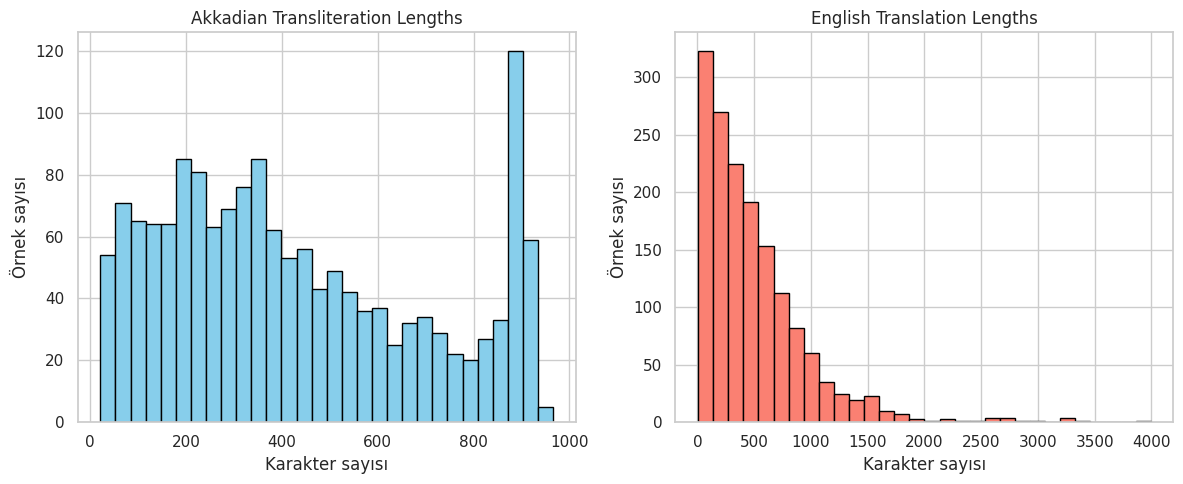

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(train_df["translit_len"], bins=30, color="skyblue", edgecolor="black")
axes[0].set_title("Akkadian Transliteration Lengths")
axes[0].set_xlabel("Karakter sayısı")
axes[0].set_ylabel("Örnek sayısı")

axes[1].hist(train_df["translation_len"], bins=30, color="salmon", edgecolor="black")
axes[1].set_title("English Translation Lengths")
axes[1].set_xlabel("Karakter sayısı")
axes[1].set_ylabel("Örnek sayısı")

plt.tight_layout()
plt.show()

**Yorum:** Transliterasyon uzunluğu ortalama ~429, medyan 371 karakter; İngilizce çeviri ortalama ~500, medyan 383 karakter. Transliterasyon dağılımı geniş yayılmış ve ~900 karakter civarında belirgin bir yığılma var (olası bir üst sınır ya da kesme etkisi). İngilizce çeviri ise sağa çarpık ve uzun kuyruklu, 4000 karaktere kadar çıkıyor. Ortalamada çeviri biraz daha uzun (~500 / ~429), ama medyanlar neredeyse aynı (383 / 371); fark, İngilizce tarafın uzun kuyruğundan geliyor.

### 3.2 En sık geçen kelimeler (transliterasyon)

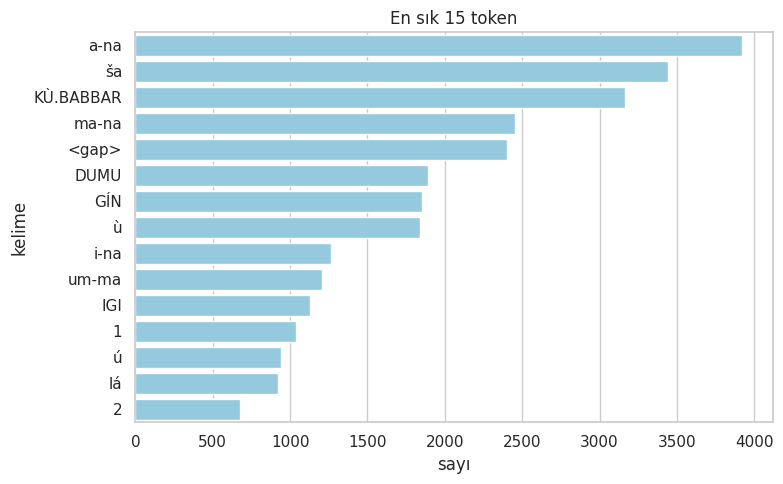

Farklı token sayısı: 11583


In [8]:
tokens = Counter(" ".join(train_df["transliteration"].dropna().astype(str)).split())
top = pd.DataFrame(tokens.most_common(15), columns=["kelime", "sayı"])

plt.figure(figsize=(8, 5))
sns.barplot(data=top, y="kelime", x="sayı", color="skyblue")
plt.title("En sık 15 token")
plt.tight_layout()
plt.show()
print("Farklı token sayısı:", len(tokens))

**Yorum:** En sık tokenlar a-na, ša, i-na, ù gibi işlevsel kelimeler, DUMU, GÍN, IGI, KÙ.BABBAR gibi ticaret metinlerine özgü sözcükler, rakamlar (1, 2) ve `<gap>` (kırık/eksik yer işareti). Toplam 11583 farklı token var; 1561 örnek için bu geniş bir kelime dağarcığı, yani veri seyrek.

### 3.3 Tekrar eden ve temizlenen metinler

In [9]:
dup_src = train_df["transliteration"].duplicated().sum()
print(f"Tekrar eden transliterasyon sayısı: {dup_src}")

# Metin temizleme fonksiyonu (src/data.py) örnek üzerinde
sample_text = train_df["transliteration"].iloc[0]
print("\nOrijinal :", sample_text[:150])
print("Temizlenmiş:", clean_akkadian_text(sample_text)[:150])

Tekrar eden transliterasyon sayısı: 2

Orijinal : KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-{d}IM KIŠIB šu-{d}EN.LÍL DUMU ma-nu-ki-a-šur KIŠIB MAN-a-šur DUMU a-ta-a 0.3333 ma-na 2 GÍN KÙ.BABBAR SIG₅ i-ṣé-er
Temizlenmiş: KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-{d}IM KIŠIB šu-{d}EN.LÍL DUMU ma-nu-ki-a-šur KIŠIB MAN-a-šur DUMU a-ta-a 0.3333 ma-na 2 GÍN KÙ.BABBAR SIG5 i-ṣé-er


**Yorum:** Train'de yalnızca 2 tekrar eden transliterasyon var, yani veri neredeyse tekrarsız. Temizleme fonksiyonu bu örnekte sadece küçük bir değişiklik yaptı (SIG₅ → SIG5).

### 3.4 Uç değerler: en kısa ve en uzun örnekler

In [10]:
def kisalt(df, n=100):
    out = df[["translit_len", "translation_len"]].copy()
    out["transliteration"] = df["transliteration"].str[:n]
    out["translation"] = df["translation"].str[:n]
    return out

print("En kısa 3 transliterasyon:")
display(kisalt(train_df.nsmallest(3, "translit_len")))
print("En uzun 3 transliterasyon:")
display(kisalt(train_df.nlargest(3, "translit_len")))
print("En uzun 3 çeviri:")
display(kisalt(train_df.nlargest(3, "translation_len")))

En kısa 3 transliterasyon:


,translit_len,translation_len,transliteration,translation
375,21,34,6 ku-ta-nu ša DAM.GÀR,6 kutānus belonging to a merchant.
125,24,33,a-ta-lá-ak ú-zu-ni pé-té,<gap> I shall go <gap> Inform us.
670,26,40,DUB ḫa-ru-mu-tum ša nu-a-e,Certified tablets concerning Anatolians.


En uzun 3 transliterasyon:


,translit_len,translation_len,transliteration,translation
13,966,1742,a-na ša-lim-a-šùr qí-bi-ma um-ma i-dí-a-bu-um ...,"To Šalim-Aššur from Iddin-abum, Itūr-ilī, Inah..."
622,949,816,1 ma-na KÙ.BABBAR ṣa-ru-pu-um i-ṣé-er <gap> DU...,<gap> son of Kumdānum owes 1 mina of refined s...
766,944,1326,a-na en-na-nim ma-ma-ḫi-ir ù a-lá-ḫi-im qí-bi-...,"To Ennānum, Man-mahir and Ali-ahum from Ennam-..."


En uzun 3 çeviri:


,translit_len,translation_len,transliteration,translation
177,935,3995,ša 4 ma-na KÙ.BABBAR ša en-na-sú-in a-na a-bi-...,As to the 4 minas of silver that Enna-Suen owe...
1090,906,3408,um-ma a-šùr-ma-lik ù ša-lim-a-šur a-na ša-lim-...,From Aššur-malik and Šalim-Aššur to Šalim-Aššu...
1377,834,3297,<gap> na <gap> PÚZUR-a-šùr DUMU a-ḫu-wa-qar iš...,"<gap> Puzur-Aššur(?), son of Ahu-waqar <gap> b..."


**Yorum:** En kısa transliterasyonlar 21-26 karakter uzunluğunda ve anlamlı kısa kayıtlar (örn. "6 kutânus belonging to a merchant"), hatalı görünmüyorlar. En uzun transliterasyonlar 944-966 karakterde, yani bir üst sınıra yakın. En uzun çeviriler ise 3300-3995 karakter ve bunların transliterasyonu yalnızca 834-935 karakter; yani çeviri, transliterasyonun yaklaşık 4 katı. Bu, uzun belgelerde transliterasyonun yaklaşık 900-1000 karakterde kesilmiş olabileceğini gösteriyor (histogramdaki yığılmayla tutarlı).

### 3.5 Akadca ve İngilizce uzunluk ilişkisi

                 translit_len  translation_len
translit_len         1.000000         0.813558
translation_len      0.813558         1.000000


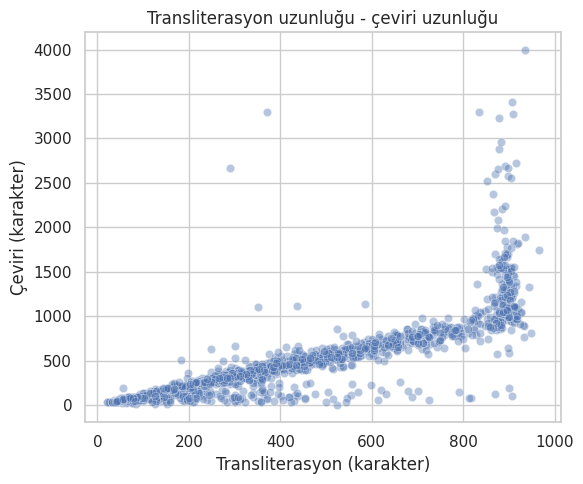

In [11]:
print(train_df[["translit_len", "translation_len"]].corr())

plt.figure(figsize=(6, 5))
sns.scatterplot(data=train_df, x="translit_len", y="translation_len", alpha=0.4)
plt.title("Transliterasyon uzunluğu - çeviri uzunluğu")
plt.xlabel("Transliterasyon (karakter)")
plt.ylabel("Çeviri (karakter)")
plt.tight_layout()
plt.show()

**Yorum:** Transliterasyon ve çeviri uzunlukları arasındaki korelasyon yaklaşık 0.81 (güçlü pozitif). Nokta bulutu çoğunlukla doğrusal artıyor, ama ~900 karakterden sonra çeviri uzunluğu keskin biçimde yükseliyor ve 3000-4000 karakterde birkaç aykırı değer var. Uzunluk, çeviri uzunluğu için iyi bir ipucu, ancak çok uzun belgelerde güvenilir değil.

### 3.6 Güven kontrolleri: `<gap>` işaretleri ve çelişkili tekrarlar

In [12]:
gap_orani = train_df["translation"].str.contains("<gap>").mean()
print(f"Çevirisinde <gap> geçen satır oranı: {gap_orani:.1%}")

# Aynı transliterasyon, farklı çeviri var mı? (çelişkili örnek)
tekrar = train_df[train_df["transliteration"].duplicated(keep=False)]
print("\nAynı transliterasyonun sahip olduğu farklı çeviri sayısı:")
print(tekrar.groupby("transliteration")["translation"].nunique())

Çevirisinde <gap> geçen satır oranı: 42.1%

Aynı transliterasyonun sahip olduğu farklı çeviri sayısı:
transliteration
40 ma-na KÙ.BABBAR ni-is-ḫa-sú DIRI ša-du-a-sú ša-bu en-um-a-šùr a-na a-lu-a ù e-ni-ša-ru-um i-na ša-la-tù-ar ku-nu-ki ip-qí-id um-ma šu-ut-ma a-na a-lim{ki} a-na ša-lim-a-šur a-bi-a bi-lá ú 5 GÍN KÙ.BABBAR a-na qá-tí-šu-nu i-dí-in a-na a-wa-tim a-ni-a-tim kà-ru-um wa-aḫ-šu-ša-na i-dí-in-ni-a-tí-ma IGI GÍR ša da-šùr ší-bu-tí-ni ni-dí-in IGI ili₅-ba-ni DUMU a-mur-a-šur IGI a-ḫu-wa-qar DUMU šu-IŠTAR tù-ra-am-ì-lí DUMU e-dí-in-a-šur tap-pá-i-ni    2
i-dí-a-bu-um É-tí ša bu-ri-im a-šar ša-lim-a-šùr wa-áš-bu iš-tí tù-ud-ḫa-li-a a-ḫu tù-li iš-a-am a-na a-wa-tim a-ni-a-tim kà-ru-um kà-ni-iš i-dí-ni-a-tí-ma ṭup-pá-am ší-bu-tí-ni IGI GÍR ša a-šùr ni-dí-in IGI a-ku-za IGI ú-ra-a IGI a-šùr-ba-ni                                                                                                                                                                                             

**Yorum:** Çevirilerin yaklaşık %42'sinde `<gap>` (kırık/eksik yer) işareti var; yani verinin büyük kısmında kaynak metin eksik ve model bu işareti de üretmeyi öğrenmek zorunda. Tekrar eden iki transliterasyonun ikisinde de iki farklı çeviri bulunuyor (çelişkili örnek). Sayı çok az olduğu için etkisi küçük, ama etiketlerin tamamen tutarlı olmadığını gösteriyor.

## 4. Baseline modelleri

Üç basit baseline, aynı train/validation bölmesiyle (%80 / %20, `random_state=42`) karşılaştırılır:

1. **Copy-input:** Akadca girdi aynen çıktı olarak verilir.
2. **Sabit cümle:** Train'deki en sık çeviri her örnek için verilir.
3. **TF-IDF en yakın komşu:** Train'deki en benzer girdinin çevirisi verilir.

Kodlar `src/models.py` içindedir. Metrikler: BLEU ve chrF (`sacrebleu`).

In [13]:
train_part, val_part = split_data(train_df)
print(f"Train: {len(train_part)} satır | Validation: {len(val_part)} satır")

results = run_baselines(train_part, val_part)
results

Train: 1248 satır | Validation: 313 satır


,Baseline,BLEU,chrF
0,Copy-input,1.29,10.55
1,Sabit cümle,2.52,22.82
2,TF-IDF en yakın komşu,15.49,35.51


**Yorum:** TF-IDF en yakın komşu yöntemi hem BLEU hem chrF bakımından açık farkla en iyi baseline oldu. Tabletlerde mühür ve "X oğlu Y" gibi kalıplar sık tekrar ettiği için, train'deki en benzer cümlenin çevirisini vermek işe yarıyor. Copy-input en düşük skoru aldı, çünkü Akadca transliterasyon ile İngilizce çeviri arasında neredeyse ortak kelime yok. Sabit cümle ise İngilizce çıktı verdiği için karakter düzeyinde (chrF) biraz puan kazandı. Skorlar rastgele train/validation bölmesiyle hesaplandı. Benzer kalıplı belgeler (mühür, borç kayıtları gibi) en yakın komşu yöntemini yükseltmiş olabilir; gerçek test skoru bundan farklı çıkabilir. Sonraki adımda geliştirilecek modellerin bu üç değeri geçmesi hedeflenmektedir.